# FLEX atmospheric correction above water: figures of the ATBD V1.1

Prototype of the atmospheric correction of FLEX pixels from the Sentinel-3 L2A atmospheric products, with
`s3flex_acaqua` 0.1.0 and the radiative transfer simulator `radcalnet_oc` 1.1. The new elements of version 1.1
of the simulator are:

- the **coupling of the gaseous absorption with the scattering**: the path reflectance, the water-leaving term
  and the downwelling irradiance have their own gaseous transmittance, given by a photon path-length model
  fitted on SOS-ABS simulations (option `gas_coupling='path_length'`), instead of the transmittance of the
  direct beam (`'decoupled'`, version 1.0 of the ATBD, where it was approximated by ad hoc scaling coefficients of
  the H$_2$O and O$_2$ optical thicknesses);
- the **line-by-line absorption of O$_2$** in the O$_2$-B and O$_2$-A bands (`o2_model='lbl'`), needed at the
  sub-nanometre resolution of FLEX;
- the look-up tables interpolated at the **wind speed** of the L2A product.

The notebook makes the figures of the ATBD (`fig_dir`): gaseous transmittances at the resolution of FLEX, impact
of the coupling on the TOA reflectance, and the processing of the two pixels of the Sentinel-3 FLEX-mode image of
the ATBD (coccolithophore bloom and sunglint).

In [1]:
import logging
import os
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
rc = {"font.family": "serif", "mathtext.fontset": "stix"}
plt.rcParams.update(rc)
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]
plt.rcParams.update({'font.size': 16, 'axes.labelsize': 18})
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import xarray as xr

import radcalnet_oc as radoc
from radcalnet_oc.kernel import GasCoupling, GAS_COUPLING_PPLD_FILE
import s3flex_acaqua

logging.getLogger().setLevel(logging.ERROR)
warnings.simplefilter('ignore')
print(f'radcalnet_oc {radoc.__version__}, s3flex_acaqua {s3flex_acaqua.__version__}')

# figures of the ATBD (local copy of the Overleaf project)
fig_dir = '/home/harmel/Dropbox/Dropbox/work/git/vrtc/radcalnet_oc/reports/ATBD_S3_FLEX_AC_water/figures'
SUFFIX = '.png'

# co-registered Sentinel-3B FLEX-mode L1 and Sentinel-3A L2A image
data_dir = '/DATA/projet/magellium/esa/phy2flex/data/sen3b'
file = os.path.join(data_dir, 'S3A_S3B_OL_1_EFR____20180702T101353_20180702T101841_20191024T140239_0287_010_065'
                              '______LR1_D_NT_stacked.zarr')
# pixels of the ATBD: coccolithophore bloom (green dot) and sunglint (red dot)
PIXELS = {'bloom': (2148.94966887, 5309.81605378), 'sunglint': (4060., 5611.)}
# aerosol model of the ATBD (desert) and aerosol optical thicknesses simulated
AEROSOL = [0., 0., 1., 0., 0., 0.]
AOT_REFS = [0.01, 0.05, 0.1, 0.2, 0.3]
# spectral resolution of FLEX/FLORIS in the O2 bands (Gaussian FWHM, nm)
FWHM_FLEX = 0.3


def savefig(fig, name):
    fig.savefig(os.path.join(fig_dir, name + SUFFIX), bbox_inches='tight', dpi=200)

radcalnet_oc 1.1.0, s3flex_acaqua 0.1.0


In [2]:
l1_prod = xr.open_zarr(file, decode_coords='all')
pixels = {name: l1_prod.sel(x=x, y=y, method='nearest').load() for name, (x, y) in PIXELS.items()}
rows = {}
for name, pt in pixels.items():
    wind = float(np.hypot(pt.horizontal_wind.isel(wind_vectors=0), pt.horizontal_wind.isel(wind_vectors=1)))
    rows[name] = {'lon': float(pt.longitude), 'lat': float(pt.latitude), 'sza': float(pt.sza), 'vza': float(pt.vza),
                  'raa': float(pt.raa), 'aot550 (L2A)': float(pt.T865) * (550 / 865) ** -float(pt.A865),
                  'A865': float(pt.A865), 'wind': wind, 'tcwv (kg m-2)': float(pt.total_columnar_water_vapour),
                  'pressure': float(pt.sea_level_pressure)}
pd.DataFrame(rows).round(3)

,bloom,sunglint
lon,2.925,11.399
lat,56.897,56.382
sza,38.247,35.360
vza,29.193,9.501
raa,39.492,225.112
aot550 (L2A),0.089,0.300
A865,1.563,0.075
wind,2.760,6.146
tcwv (kg m-2),13.619,11.543
pressure,1022.972,1018.811


## Gaseous transmittances at the resolution of FLEX

Transmittances for the atmosphere of the bloom pixel (L2A water vapour, pressure and AOT, geometry of the pixel),
convolved with Gaussian responses of 0.3 nm FWHM: the direct beam of the Sun-surface-sensor path
$T_g(m)$, $m = 1/\mu_0 + 1/\mu_v$ (decoupled model, applied to all the terms in version 1.0), and the coupled
transmittances of the path reflectance $T_g^{atm}$ and of the water-leaving term $T_g^{w}$.

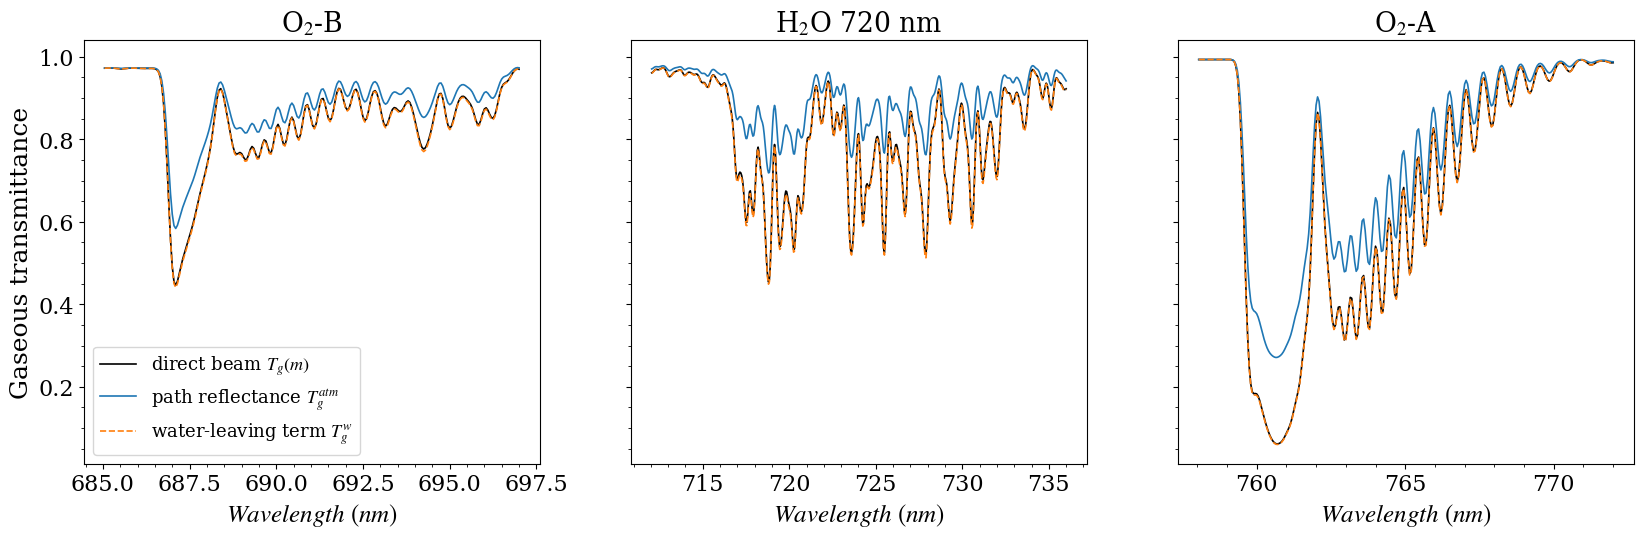

,O$_2$-B,H$_2$O 720 nm,O$_2$-A
max T_atm / T_direct,1.309,1.583,4.401
mean T_atm / T_direct,1.056,1.134,1.355
max |T_w / T_direct - 1| (%),1.201,1.695,2.274


In [3]:
pt = pixels['bloom']
mu0, muv = np.cos(np.radians(float(pt.sza))), np.cos(np.radians(float(pt.vza)))
m = 1 / mu0 + 1 / muv
aot550 = rows['bloom']['aot550 (L2A)']
lut = radoc.LUT()
flex = radoc.Spectral(np.arange(680., 780., 0.05), FWHM_FLEX)


def at_flex(T):
    out = flex.convolve2(T.sel(wl=slice(675, 785)).rename('T'), expon=2)
    return (out[list(out.data_vars)[0]] if isinstance(out, xr.Dataset) else out).squeeze(drop=True)


def gas(o2_model='lbl'):
    g = radoc.GaseousTransmittance(lut.gas_lut, o2_model=o2_model)
    g.pressure = float(pt.sea_level_pressure)
    g.gas_tc['h2o'] = float(pt.total_columnar_water_vapour)
    g.gas_tc['o3'] = float(pt.total_ozone)
    g.air_mass = m
    return g


g = gas()
coupling = GasCoupling(GAS_COUPLING_PPLD_FILE)
T = {'direct': at_flex(g.get_gaseous_transmittance()),
     'atm': at_flex(g.get_coupled_transmittance(m, 'atm', aot550, coupling)),
     'w': at_flex(g.get_coupled_transmittance(m, 'w', aot550, coupling))}
g_reptran = gas('reptran')
T['direct, REPTRAN O$_2$'] = at_flex(g_reptran.get_gaseous_transmittance())

windows = {'O$_2$-B': slice(685, 697), 'H$_2$O 720 nm': slice(712, 736), 'O$_2$-A': slice(758, 772)}
styles = {'direct': dict(c='k', label=r'direct beam $T_g(m)$'),
          'atm': dict(c='tab:blue', label=r'path reflectance $T_g^{atm}$'),
          'w': dict(c='tab:orange', ls='--', label=r'water-leaving term $T_g^{w}$')}
fig, axs = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True)
for ax, (name, wl_range) in zip(axs, windows.items()):
    for key, kw in styles.items():
        T[key].sel(wl=wl_range).plot(ax=ax, lw=1.2, **kw)
    ax.set_title(name)
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel('')
    ax.minorticks_on()
axs[0].set_ylabel('Gaseous transmittance')
axs[0].legend(fontsize=13, loc='lower left')
savefig(fig, 'gas_coupling_flex')
plt.show()

stats = {}
for name, wl_range in windows.items():
    ratio = (T['atm'] / T['direct']).sel(wl=wl_range)
    stats[name] = {'max T_atm / T_direct': float(ratio.max()), 'mean T_atm / T_direct': float(ratio.mean()),
                   'max |T_w / T_direct - 1| (%)': float(100 * abs(T['w'] / T['direct'] - 1).sel(wl=wl_range).max())}
pd.DataFrame(stats).round(3)

### Line-by-line O$_2$

At 0.3 nm, the REPTRAN parameterization (fine table of about 0.06 nm, made for broader bands) overestimates the
absorption of the O$_2$ bands compared with the line-by-line computation: the transmittance of the O$_2$-B band
head is about halved, and the lines of the P branch of the O$_2$-A band are deeper.

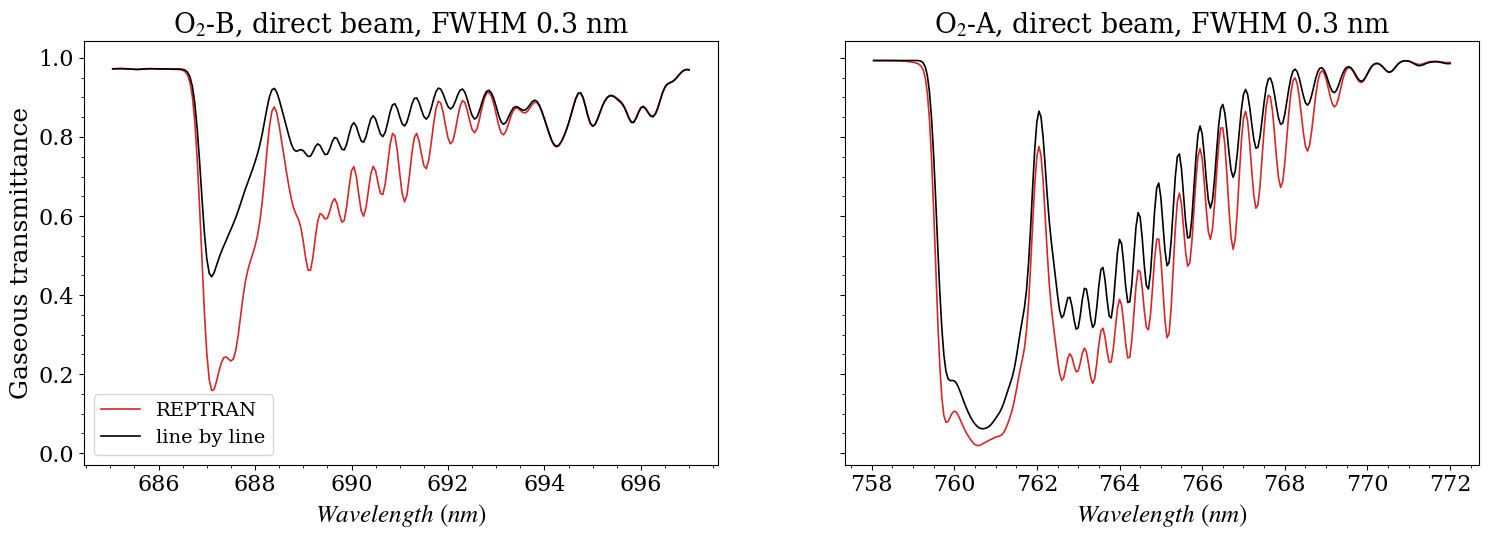

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(18, 5.5), sharey=True)
for ax, name in zip(axs, ['O$_2$-B', 'O$_2$-A']):
    T['direct, REPTRAN O$_2$'].sel(wl=windows[name]).plot(ax=ax, c='tab:red', lw=1.2, label='REPTRAN')
    T['direct'].sel(wl=windows[name]).plot(ax=ax, c='k', lw=1.2, label='line by line')
    ax.set_title(name + r', direct beam, FWHM 0.3 nm')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel('')
    ax.minorticks_on()
axs[0].set_ylabel('Gaseous transmittance')
axs[0].legend(fontsize=14)
savefig(fig, 'o2_lbl_reptran_flex')
plt.show()

## Impact of the coupling on the atmospheric reflectance

Atmospheric reflectance at the TOA, $T_g^{atm} R_{atm}$, of the bloom pixel (L2A aerosol optical thickness),
computed with the coupled transmittance (version 1.1) and with the direct-beam transmittance, at 0.3 nm.

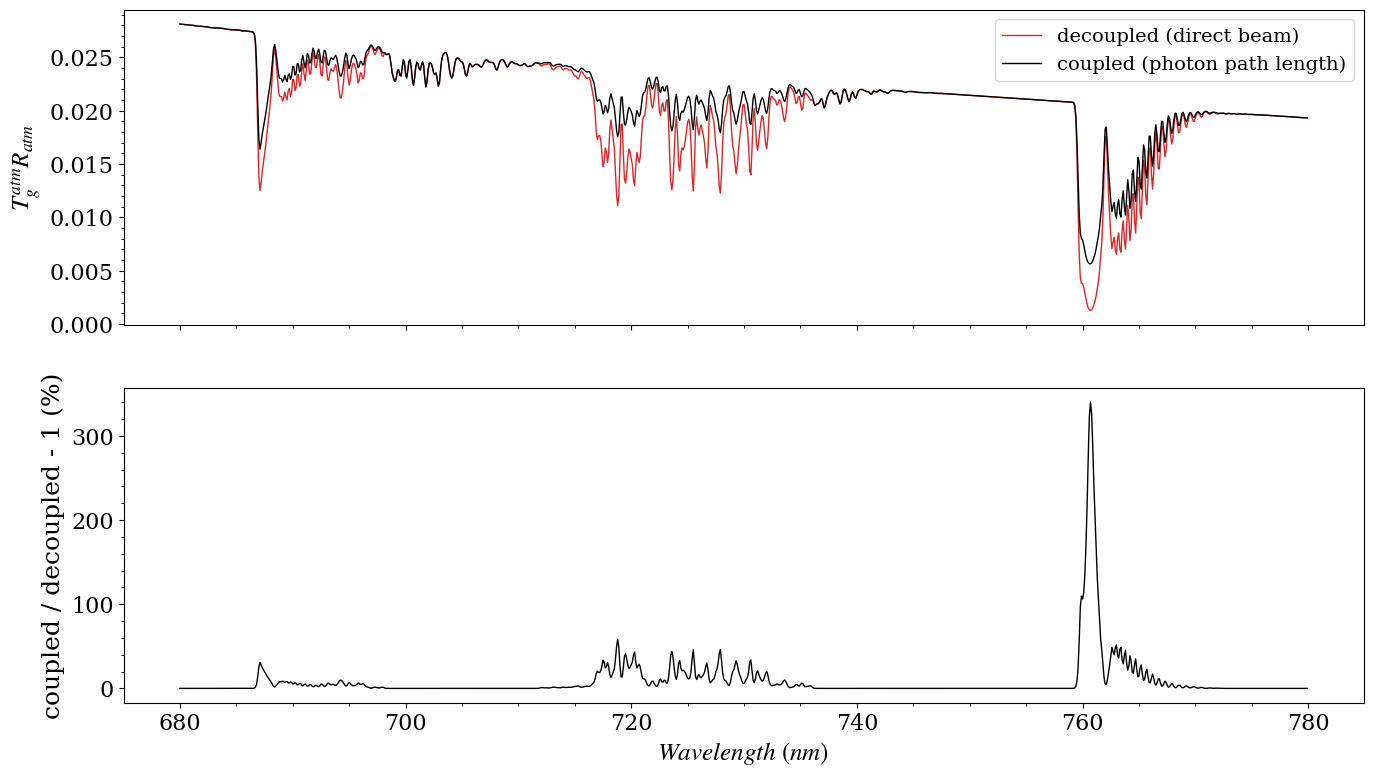

O$_2$-B           30.9
H$_2$O 720 nm     58.3
O$_2$-A          340.1
Name: max difference (%), dtype: float64

In [5]:
runs = {c: s3flex_acaqua.Process(gas_coupling=c).execute(pt, wl_min=500, wl_max=800, aot_refs=[aot550],
                                                         aerosol_combination=AEROSOL)
        for c in ['path_length', 'decoupled']}
fig, axs = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
for c, kw in {'decoupled': dict(c='tab:red', label='decoupled (direct beam)'),
              'path_length': dict(c='k', label='coupled (photon path length)')}.items():
    runs[c].Ratm.sel(wl=slice(680, 780)).plot(ax=axs[0], lw=1, **kw)
rel = 100 * (runs['path_length'].Ratm / runs['decoupled'].Ratm - 1)
rel.sel(wl=slice(680, 780)).plot(ax=axs[1], c='k', lw=1)
axs[0].set_ylabel(r'$T_g^{atm} R_{atm}$')
axs[0].set_xlabel('')
axs[1].set_ylabel('coupled / decoupled - 1 (%)')
axs[0].legend(fontsize=14)
for ax in axs:
    ax.set_title('')
    ax.minorticks_on()
axs[1].set_xlabel(r'$Wavelength\ (nm)$')
savefig(fig, 'ratm_gas_coupling_flex')
plt.show()
pd.Series({name: float(rel.sel(wl=w).max()) for name, w in windows.items()}, name='max difference (%)').round(1)

## Processing of the Sentinel-3 FLEX-mode pixels

The pixels are processed with `s3flex_acaqua.Process` (version 0.1.0, coupled gaseous transmittances,
line-by-line O$_2$, wind speed of the L2A product) for several aerosol optical thicknesses at 550 nm, the
desert aerosol model and the isotropic Cox-Munk statistics of the sunglint.

In [6]:
cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=0, vmax=0.4)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
RANGES = [slice(380, 1000), slice(500, 800), slice(680, 775), slice(750, 770)]


def colorbar(fig, ax):
    cax = ax.inset_axes([0.55, 0.88, 0.4, 0.03])
    cb = fig.colorbar(sm, cax=cax, orientation='horizontal')
    cb.ax.set_title(r'$aot(550nm)$', fontsize=16)


def plot_hyp(proc, pt, glint=True, convolved=False):
    fig, axs = plt.subplots(2, 2, figsize=(16, 10))
    axs = axs.ravel()
    for ax, wl_range in zip(axs, RANGES):
        for aot in proc.Ratm.aot_ref.values:
            c = cmap(norm(aot))
            Ratm = proc.Ratm.sel(aot_ref=aot).sel(wl=wl_range)
            total = (proc.Ratm + proc.Rtoa_sunglint).sel(aot_ref=aot).sel(wl=wl_range)
            if convolved:
                total.plot(ax=ax, color=c, lw=0.6, alpha=0.6)
                bands = (proc.Ratm_sat + proc.Rtoa_sunglint_sat).sel(aot_ref=aot).sel(wl=wl_range)
                ax.plot(bands.wl, bands, 'o', color=c, ms=4, alpha=0.9)
            else:
                if glint:
                    Ratm.plot(ax=ax, color=c, lw=0.6, ls=':')
                total.plot(ax=ax, color=c, lw=1.3)
        pt.Rtoa.sel(wl=wl_range).plot(ax=ax, ms=4, c='k', ls=':', lw=0.3, marker='o', zorder=6)
        ax.axhline(0, ls=':', lw=0.8, c='k')
        ax.set_title('')
        ax.set_xlabel(r'$Wavelength\ (nm)$')
        ax.set_ylabel(r'$R_{TOA}\ (-)$')
        ax.minorticks_on()
    axs[0].text(0.98, 0.98, proc.params, transform=axs[0].transAxes, ha='right', va='top', fontsize=13)
    colorbar(fig, axs[1])
    return fig

### Pixel in the coccolithophore bloom

Hyperspectral simulation of the atmospheric and sunglint terms for aerosol optical thicknesses of 0.01 to 0.3,
compared with the TOA reflectance of the S3-FLEX-mode pixel (black dots), then convolved with the spectral
responses of the S3-FLEX-mode bands.

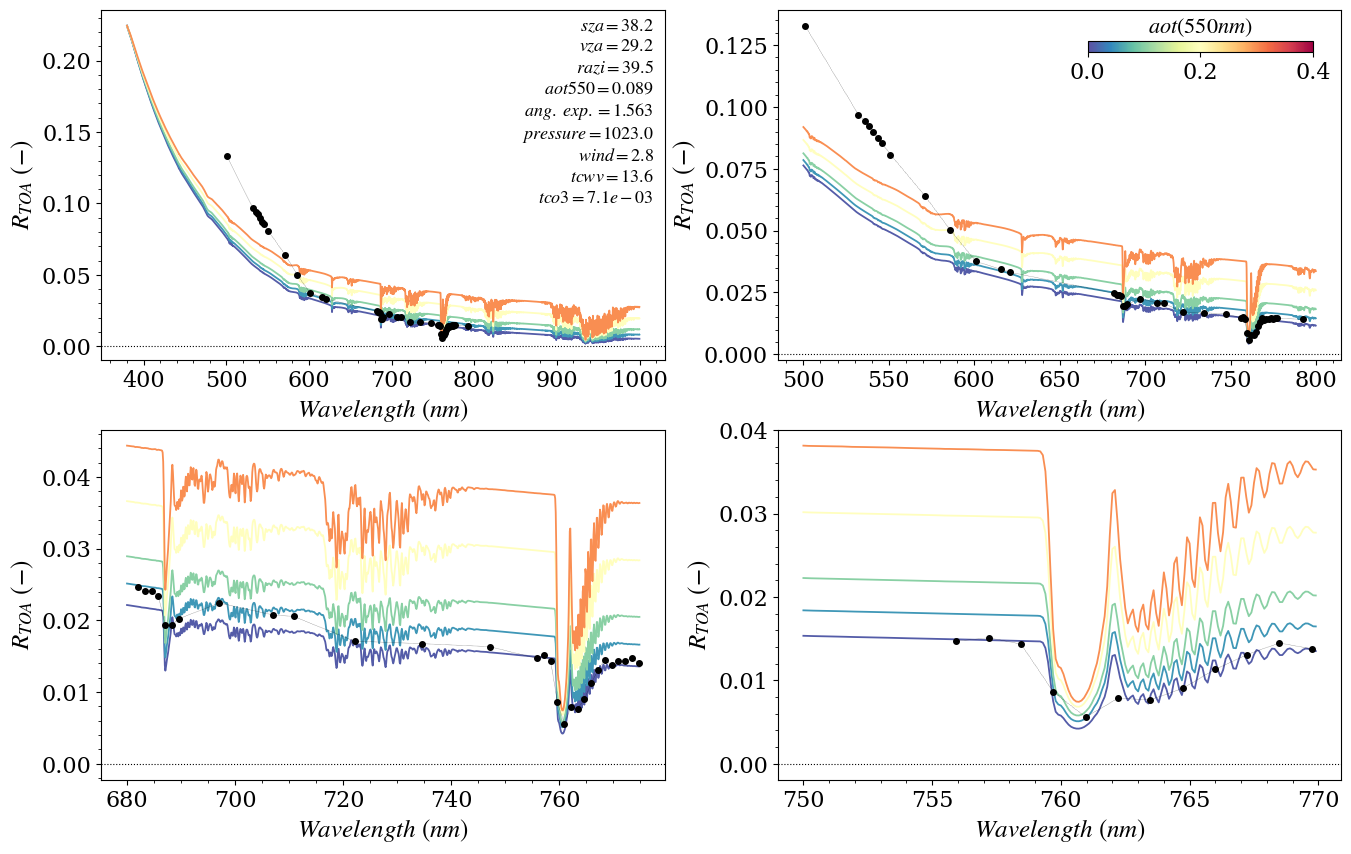

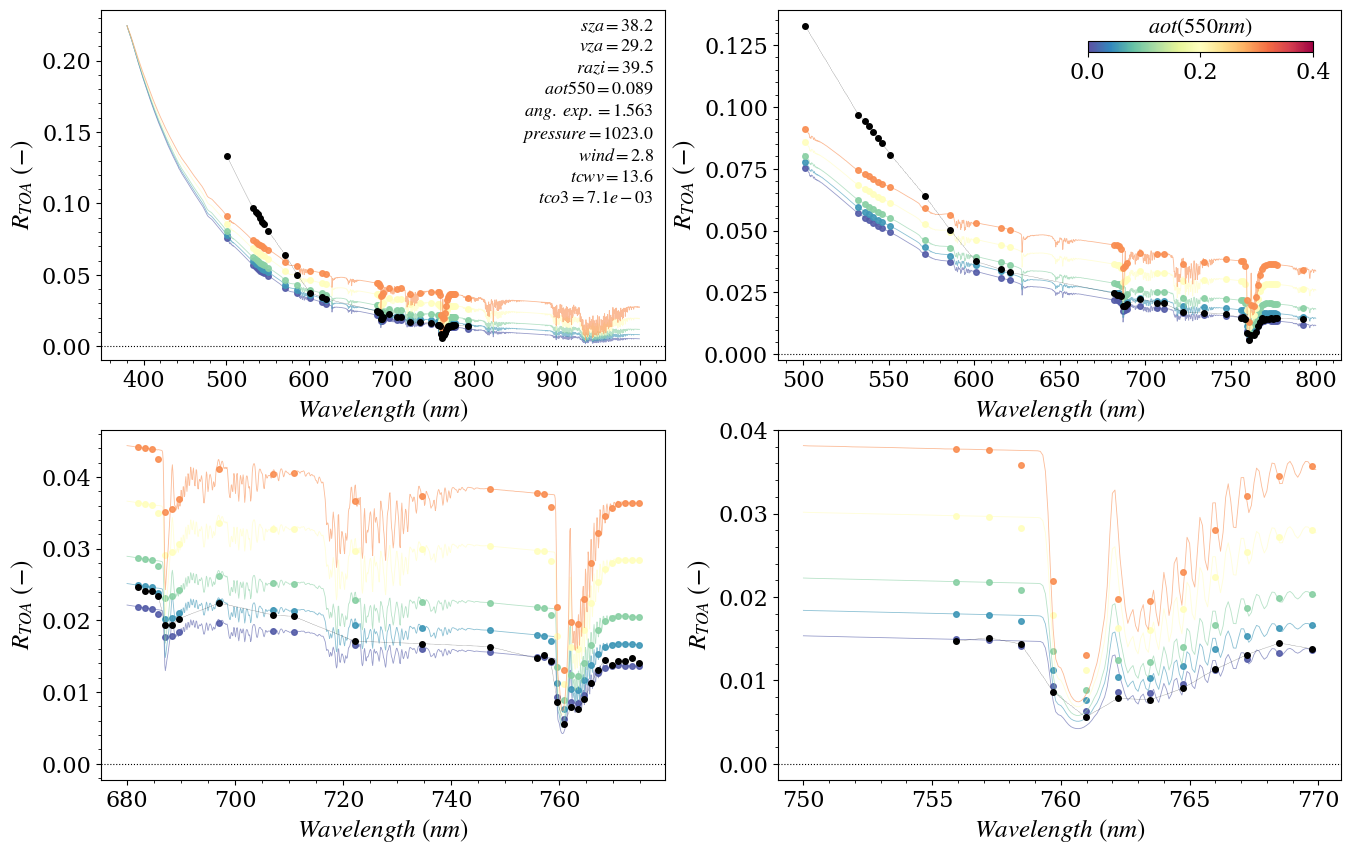

In [7]:
bloom = s3flex_acaqua.Process().execute(pixels['bloom'], wl_min=380, wl_max=1000, aot_refs=AOT_REFS,
                                       aerosol_combination=AEROSOL)
fig = plot_hyp(bloom, pixels['bloom'], glint=False)
savefig(fig, 'basic_pixel_hyp_simu')
plt.show()
fig = plot_hyp(bloom, pixels['bloom'], convolved=True)
savefig(fig, 'basic_pixel_convolved')
plt.show()

The aerosol optical thickness of the L2A product overestimates the atmospheric signal in the near infrared. As in
the ATBD V1.0, it is lowered before the final correction: here, it is set to the value that cancels the mean
water-leaving term of the bands beyond 770 nm (outside the O$_2$-A band), where the bloom has a negligible
signal, by linear interpolation between the simulated values.

mean water term beyond 770 nm: {0.01: np.float64(0.00105), 0.05: np.float64(-0.00197), 0.1: np.float64(-0.0058), 0.2: np.float64(-0.01363), 0.3: np.float64(-0.02155)}
aot(550) cancelling it: 0.024 (L2A: 0.089)


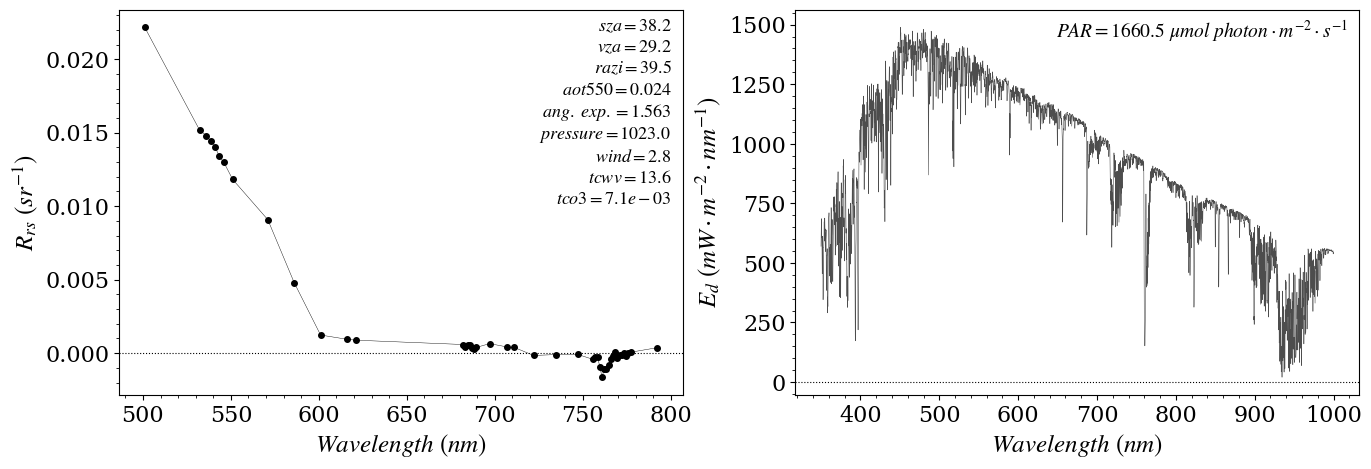

aot550         0.02395
PAR         1660.48218
Rrs(560)       0.01183
Rrs(665)       0.00059
dtype: float64

In [8]:
nir = [b for b in bloom.Rw_toa.wl.values if b >= 770]
mean_nir = bloom.Rw_toa.sel(wl=nir).mean('wl')
aot_black = float(np.interp(0., mean_nir.values[::-1], mean_nir.aot_ref.values[::-1]))
print(f'mean water term beyond 770 nm: {dict(zip(AOT_REFS, mean_nir.values.round(5)))}')
print(f'aot(550) cancelling it: {aot_black:.3f} (L2A: {aot550:.3f})')

final = s3flex_acaqua.Process().execute(pixels['bloom'], wl_min=350, wl_max=1000, aot_refs=[aot_black],
                                       aerosol_combination=AEROSOL)
Rrs = final.Rrs.squeeze()
Ed = final.Ed.squeeze()
PAR = float(final.PAR.squeeze())

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
Rrs.plot(ax=axs[0], lw=0.3, ms=4, marker='o', c='k', zorder=6)
axs[0].set_ylabel(r'$R_{rs}\ (sr^{-1})$')
axs[0].text(0.98, 0.98, final.params.replace('aot550 = %.3f' % final.inputs['aot550'], 'aot550 = %.3f' % aot_black),
            transform=axs[0].transAxes, ha='right', va='top', fontsize=13)
Ed.plot(ax=axs[1], lw=0.4, c='0.3')
axs[1].set_ylabel(r'$E_d\ (mW\cdot m^{-2}\cdot nm^{-1})$')
axs[1].text(0.98, 0.98, r'$PAR = %.1f\ \mu mol\ photon\cdot m^{-2}\cdot s^{-1}$' % PAR, transform=axs[1].transAxes,
            ha='right', va='top', fontsize=14)
for ax in axs:
    ax.axhline(0, ls=':', lw=0.8, c='k')
    ax.set_title('')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()
savefig(fig, 'basic_pixel_rrs')
plt.show()
pd.Series({'aot550': aot_black, 'PAR': PAR, 'Rrs(560)': float(Rrs.sel(wl=560, method='nearest')),
           'Rrs(665)': float(Rrs.sel(wl=665, method='nearest'))}).round(5)

### Pixel impacted by sunglint

Same simulation for the sunglint pixel (wind speed of the L2A product): dotted lines without the sunglint,
continuous lines with it.

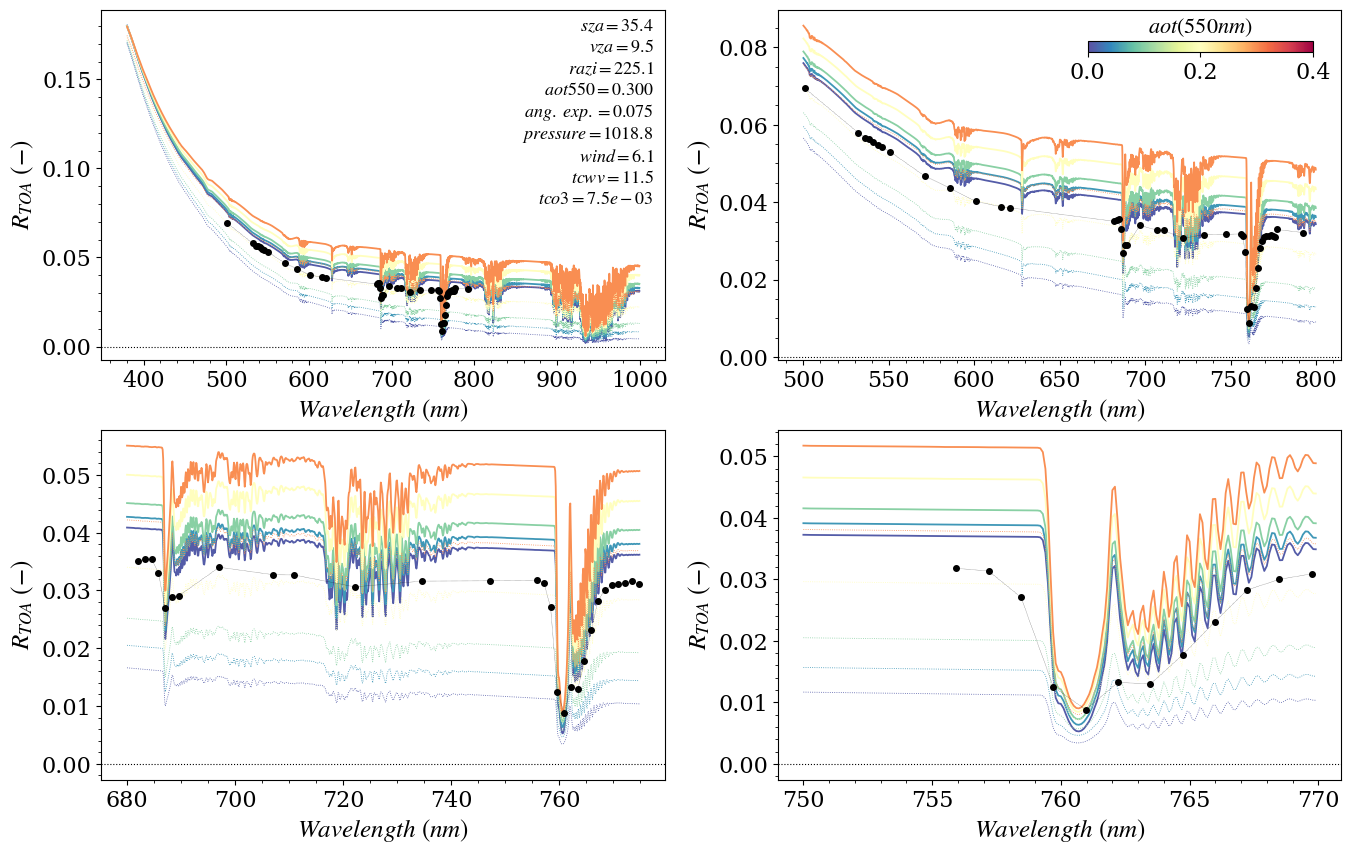

sunglint reflectance at the surface R_sg = 0.0280, L2A aot(550) = 0.300


,simulated (mean > 770 nm),measured
aot_ref,,
0.01,0.0359,0.0316
0.05,0.0378,0.0316
0.10,0.0402,0.0316
0.20,0.0451,0.0316
0.30,0.0503,0.0316


In [9]:
glint = s3flex_acaqua.Process().execute(pixels['sunglint'], wl_min=380, wl_max=1000, aot_refs=AOT_REFS,
                                       aerosol_combination=AEROSOL)
fig = plot_hyp(glint, pixels['sunglint'])
savefig(fig, 'sunglint_pixel_hyp_simu')
plt.show()
sim = (glint.Ratm_sat + glint.Rtoa_sunglint_sat).sel(wl=[w for w in glint.Ratm_sat.wl.values if w > 770])
print(f'sunglint reflectance at the surface R_sg = {glint.Rsg:.4f}, L2A aot(550) = {glint.inputs["aot550"]:.3f}')
pd.DataFrame({'simulated (mean > 770 nm)': sim.mean('wl').to_series(),
              'measured': float(pixels['sunglint'].Rtoa.sel(wl=sim.wl).mean())}).round(4)

## Comparison with water optics simulations (invRrs)

The $R_{rs}$ retrieved for the bloom pixel (aot(550) cancelling the near-infrared water term) is compared with
$R_{rs}$ simulated with the forward model of `invRrs` for six phytoplankton species of the HABLAB inherent optical
properties (HET: *Heterosigma akashiwo*, CHA: *Chaetoceros muelleri*, EMI: *Emiliania huxleyi*, LEP:
*Lepidodinium chlorophorum*, LIN: *Lingulodinium polyedra*, PRY: *Prymnesium parvum*) and several chlorophyll-a
concentrations, with the settings of the ATBD V1.0: absorption of CDOM of 0.015 m$^{-1}$ at 440 nm (slope
0.017 nm$^{-1}$), mineral particles (Mie, $n = 1.17 - 0.0001i$, normalized concentration 0.075), sun-induced
fluorescence (Gower et al., 2004) added with the downwelling irradiance of the correction, viewing zenith angle
40° and relative azimuth 90° for the bidirectional coefficients.

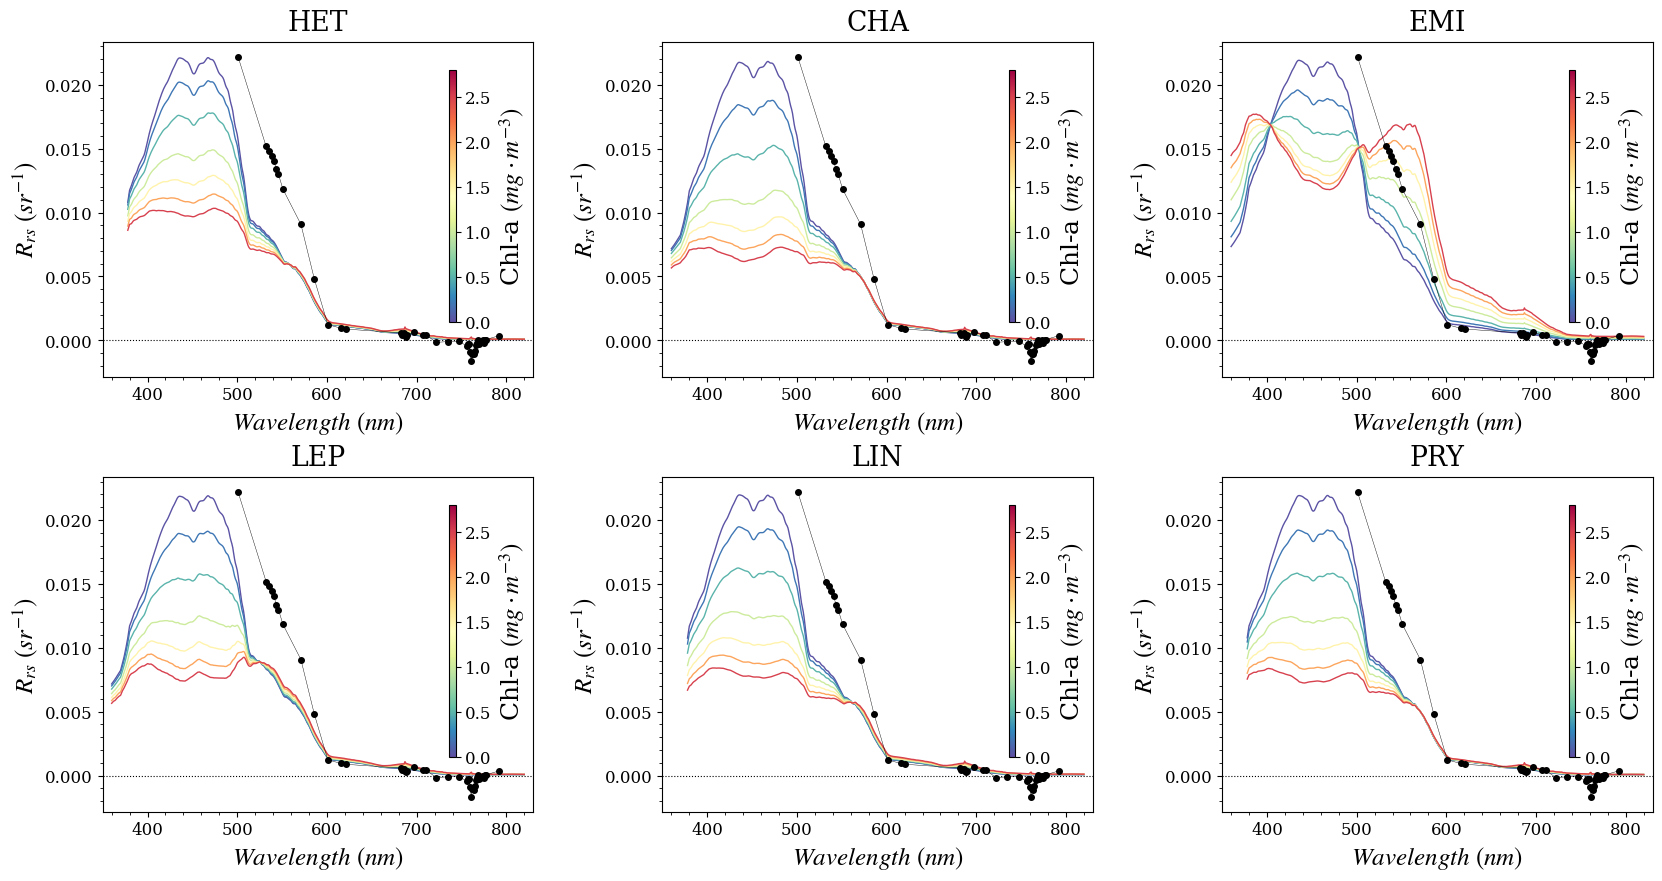

In [10]:
from invRrs import solver

xiops = xr.open_dataset('/DATA/projet/gernez/hablab/2023_HABLAB/xiops_hablab_v20250612.nc')
xmie = xr.open_dataset('/DATA/git/vrtc/invRrs/data/lut/mie_iops_v2023.nc')
SPECIES = ['HET', 'CHA', 'EMI', 'LEP', 'LIN', 'PRY']
CHLS = [0.03, 0.2, 0.5, 1, 1.5, 2, 2.5]
acdom440, Scdom, spm_norm = 0.015, 0.017, 0.075
nr, ni, mix = 1.17, -0.0001, [0.8, 0.15, 0.05]
vza_w, azi_w = 40, 90
sza = final.inputs['sza']

wl = np.arange(350., 1000., 1.)
Ed1 = Ed.interp(wl=wl)
Ed_ref = Ed.sel(wl=slice(400, 700)).mean()
Cbscat = sum(m * xmie.isel(spm=0, rm=i).Cbscat_vol.interp(wl=wl, method='quadratic').interp(nr=nr, ni=ni)
             for i, m in enumerate(mix))
Cabs = sum(m * xmie.isel(spm=0, rm=i).Cabs_vol.interp(wl=wl, method='quadratic').interp(nr=nr, ni=ni)
           for i, m in enumerate(mix))
acdom = acdom440 * np.exp(-Scdom * (wl - 440))


def rrs_species(species, chl):
    # Rrs of invRrs (with sun-induced fluorescence) for a species and a chlorophyll-a concentration
    xi = xiops.sel(species=species).interp(wl=wl)
    simu = solver.Rrs_inversion(xi.aph_star, xi.bbp_star, sza, wl_=xr.DataArray(wl, coords={'wl': wl}, dims='wl'))
    simu.set_coef(sza, vza_w, azi_w)
    atot = simu.aphy_star * chl + acdom + Cabs * spm_norm * (1. + .02 * chl)
    bbtot = simu.bbphy_star * chl + Cbscat * spm_norm * (1. + .02 * chl)
    Rrs_ = simu.simple_forward_model(atot, bbtot, vza=vza_w, azi=azi_w, sza=sza, chl=chl)
    fluo = (Ed_ref * simu.fluo_gower2004(chl)).interp(wl=wl)
    return ((Rrs_ * Ed1 + fluo) / Ed1).reset_coords(drop=True)


cmap_chl = plt.cm.Spectral_r
norm_chl = mpl.colors.Normalize(vmin=0, vmax=2.8)
sm_chl = mpl.cm.ScalarMappable(norm=norm_chl, cmap=cmap_chl)
fig, axs = plt.subplots(2, 3, figsize=(20, 10))
fig.subplots_adjust(hspace=0.3, wspace=0.3)
for ax, species in zip(axs.ravel(), SPECIES):
    for chl in CHLS:
        rrs_species(species, chl).plot(ax=ax, lw=1, color=cmap_chl(norm_chl(chl)))
    Rrs.plot(ax=ax, lw=0.3, ms=4, marker='o', c='k', zorder=6)
    ax.axhline(0, ls=':', lw=0.8, c='k')
    cax = ax.inset_axes([0.72, 0.07, 0.1, 0.94])
    cax.set_axis_off()
    cb = fig.colorbar(sm_chl, ax=cax, shrink=0.8, aspect=40)
    cb.set_label(r'Chl-a $(mg\cdot m^{-3})$', fontsize=18)
    ax.set_title(species)
    ax.set_xlim(350, 830)
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$R_{rs}\ (sr^{-1})$')
    ax.minorticks_on()
savefig(fig, 'Rrs_simu_basic_pixel')
plt.show()

Best chlorophyll-a concentration of each species (grid of 0.01 to 3 mg m$^{-3}$) and root mean square difference
with the retrieved $R_{rs}$ in the bands of 500 to 750 nm, outside the O$_2$-B band:

In [11]:
bands = [b for b in Rrs.wl.values if 500 <= b <= 750 and not (684 <= b <= 700)]
obs = Rrs.sel(wl=bands)
chl_grid = np.round(np.concatenate([np.arange(0.01, 0.1, 0.01), np.arange(0.1, 3.01, 0.05)]), 3)
fits = {}
for species in SPECIES:
    rmsd = [float(np.sqrt(((rrs_species(species, c).interp(wl=bands) - obs) ** 2).mean())) for c in chl_grid]
    i = int(np.argmin(rmsd))
    fits[species] = {'chl (mg m-3)': chl_grid[i], 'RMSD (sr-1)': rmsd[i],
                     'RMSD / mean Rrs (%)': 100 * rmsd[i] / float(obs.mean())}
pd.DataFrame(fits).T.sort_values('RMSD (sr-1)').round(5)

,chl (mg m-3),RMSD (sr-1),RMSD / mean Rrs (%)
EMI,1.15,0.00196,28.59612
LEP,0.01,0.00411,59.81630
HET,0.01,0.00411,59.86849
PRY,0.01,0.00411,59.90463
LIN,0.01,0.00411,59.93518
CHA,0.01,0.00412,59.94846
